# 1.5 (1 dalis) — Iš anksto išmokyti vaizdų modeliai laboratorinio reikmens nuotraukai

**Pritaikyta iš kurso** [Transfer learning 1](https://colab.research.google.com/drive/1h7GEPDd4ldfEa0J2dJiFO2d2bQATAqsp?usp=sharing).

**Ką daro originalas.** Naujam vaizdui taiko jau išmokytus modelius: ImageNet klasifikatorius (palygina kelis), parodo, kaip apkirpimas keičia prognozę, taiko objektų aptikimo ir semantinės segmentacijos modelius. Naujas modelis **nemokomas**.

**Kas pakeista.** Įvestis — tikros laboratorinių reikmenų nuotraukos iš mūsų **testo aibės** (po vieną kiekvienos klasės). Tikslas — parodyti, ką bendras modelis atpažįsta ir **ko nežino**: ImageNet ir Open Images turi bendrų daiktų klases, bet ne „PCR mėgintuvėlio juostelė“ ar „96 šulinėlių plokštelė“, ir tikrai ne tūrio, sterilumo ar gamintojo. Tai motyvuoja 2 dalį, kur mokoma nauja klasifikavimo galvutė.


## Duomenys ir jų ryšys su klientu

Kliento katalogo kainynuose yra **vizualiai atpažįstamų laboratorinių reikmenų** (plastikiniai PCR ir pipetavimo reikmenys). Naudojamos trys klasės:

| Klasė | Kas tai | Atitikmuo kataloge |
|---|---|---|
| `antgaliai` | pipečių antgaliai, antgalių dėžutės / stoveliai | filtruoti antgaliai stoveliuose |
| `mikro_megintuvelis` | PCR mėgintuvėliai, 8 mėgintuvėlių juostelės, 1,5 ml mikromėgintuvėliai | PCR mėgintuvėliai ir juostelės |
| `mikroplokstele` | 96 / 384 / 24 / 6 šulinėlių plokštelės | PCR plokštelės, mikroplokštelės |

**Kilmė.** Tai **viešos nuotraukos iš Wikimedia Commons ir Openverse (Flickr ir kt.)**, ne kliento ir ne studento darytos. Kiekviena nuotrauka rankiniu būdu peržiūrėta; atmesti piešiniai, įranga ir scenos, kur daiktas nepagrindinis. Licencijos (CC0, viešas naudojimas, CC BY, CC BY-SA, CC BY-NC / NC-SA) ir autoriai išsaugoti `metadata.csv`; CC BY / BY-SA reikalauja nurodyti autorių pristatyme.

**Padalijimas.** Visos vieno autoriaus nuotraukos patenka į tą pačią `train` / `val` / `test` aibę, kad tos pačios fotosesijos ar fono kadrai nebūtų ir mokyme, ir teste.

**Paskirtis ir ribos.** Tai **pagalbinė katalogo / sandėlio prekių grupavimo užduotis**, ne pirkimų dokumentų analizė. Iš nuotraukos negalima nustatyti tūrio, sterilumo, gamintojo ar SKU. Rinkinys mažas, todėl rezultatai turi didelę paklaidą.


## 1. Pasirinkti po vieną testo nuotrauką kiekvienai klasei


train {'antgaliai': 41, 'mikro_megintuvelis': 34, 'mikroplokstele': 54} iš viso 129
val   {'antgaliai': 9, 'mikro_megintuvelis': 8, 'mikroplokstele': 12} iš viso 29
test  {'antgaliai': 13, 'mikro_megintuvelis': 10, 'mikroplokstele': 16} iš viso 39
TensorFlow 2.19.0


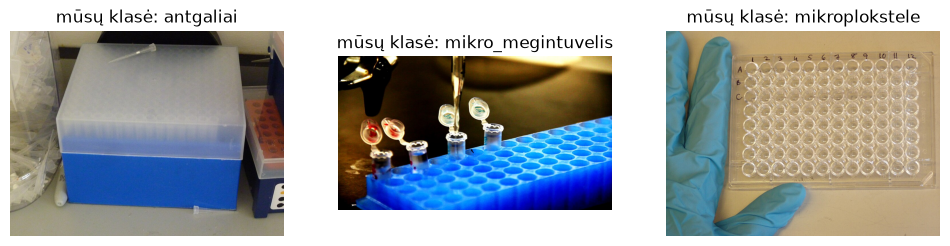

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = Path(os.getenv("TENDER_FIT_IMAGES_DIR", PROJECT / "private" / "1_4_vaizdai" / "galutinis"))
CLASS_NAMES = ["antgaliai", "mikro_megintuvelis", "mikroplokstele"]
assert DATA_ROOT.exists(), f"Nerastas {DATA_ROOT}"
for split in ("train", "val", "test"):
    counts = {c: len(list((DATA_ROOT / split / c).glob("*.jpg"))) for c in CLASS_NAMES}
    print(f"{split:5}", counts, "iš viso", sum(counts.values()))
print("TensorFlow", tf.__version__)

from PIL import Image
examples = {c: sorted((DATA_ROOT / "test" / c).glob("*.jpg"))[0] for c in CLASS_NAMES}
raw_images = {c: np.asarray(Image.open(p).convert("RGB")) for c, p in examples.items()}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (c, img) in zip(axes, raw_images.items()):
    ax.imshow(img); ax.set_title(f"mūsų klasė: {c}"); ax.axis("off")
plt.show()


## 2. Du ImageNet klasifikatoriai

MobileNetV2 ir EfficientNetB0 grąžina **ImageNet** klases (1000 bendrų daiktų). Pasitikėjimo reikšmė nėra tikimybė, kad tai mūsų klasės prekė.


In [2]:
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess, decode_predictions

mobile = MobileNetV2(weights="imagenet")
efficient = EfficientNetB0(weights="imagenet")

def top3(image_array):
    resized = tf.image.resize(image_array, (224, 224))[None, ...]
    m = decode_predictions(mobile.predict(mobilenet_preprocess(tf.identity(resized)), verbose=0), top=3)[0]
    e = decode_predictions(efficient.predict(resized, verbose=0), top=3)[0]
    return [(l, round(float(p), 3)) for _, l, p in m], [(l, round(float(p), 3)) for _, l, p in e]

rows = []
for c, img in raw_images.items():
    m, e = top3(img)
    rows.append({"mūsų klasė": c, "MobileNetV2 top-3": m, "EfficientNetB0 top-3": e})
pd.set_option("display.max_colwidth", 200)
pd.DataFrame(rows)


,mūsų klasė,MobileNetV2 top-3,EfficientNetB0 top-3
0,antgaliai,"[(carton, 0.591), (toilet_tissue, 0.224), (paper_towel, 0.078)]","[(carton, 0.549), (desk, 0.027), (chest, 0.026)]"
1,mikro_megintuvelis,"[(hook, 0.199), (perfume, 0.147), (sewing_machine, 0.026)]","[(stage, 0.063), (honeycomb, 0.047), (perfume, 0.046)]"
2,mikroplokstele,"[(honeycomb, 0.148), (pillow, 0.067), (radiator, 0.051)]","[(tray, 0.185), (handkerchief, 0.176), (honeycomb, 0.072)]"


## 3. Apkirpimas keičia prognozę

Apkirpus centrinę dalį, keičiasi kontekstas ir mastelis. Bendras modelis jautrus tokiam paruošimui.


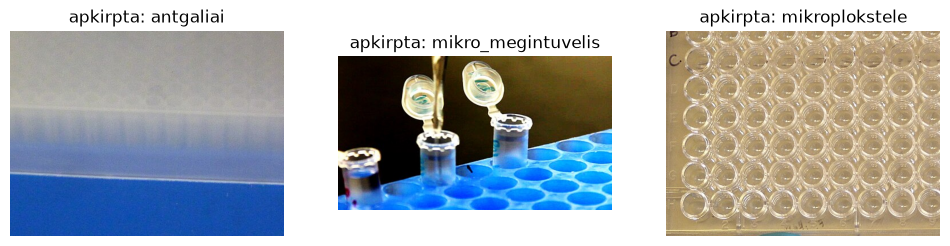

,mūsų klasė,MobileNetV2 top-3 (apkirpta),EfficientNetB0 top-3 (apkirpta)
0,antgaliai,"[(wing, 0.067), (airliner, 0.051), (dam, 0.037)]","[(balance_beam, 0.077), (rule, 0.062), (envelope, 0.061)]"
1,mikro_megintuvelis,"[(beaker, 0.483), (corkscrew, 0.173), (perfume, 0.044)]","[(pill_bottle, 0.444), (honeycomb, 0.046), (pop_bottle, 0.033)]"
2,mikroplokstele,"[(honeycomb, 0.317), (chain_mail, 0.168), (bubble, 0.147)]","[(tray, 0.182), (doormat, 0.085), (shower_curtain, 0.082)]"


In [3]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (c, img) in zip(axes, raw_images.items()):
    h, w = img.shape[:2]
    crop = img[h // 4: 3 * h // 4, w // 4: 3 * w // 4]
    ax.imshow(crop); ax.set_title(f"apkirpta: {c}"); ax.axis("off")
    m, e = top3(crop)
    rows.append({"mūsų klasė": c, "MobileNetV2 top-3 (apkirpta)": m, "EfficientNetB0 top-3 (apkirpta)": e})
plt.show()
pd.DataFrame(rows)


## 4. Objektų aptikimas (Open Images, 600 klasių)

Aptikimo modelis grąžina stačiakampius ir bendras objektų klases. Jei laboratorinio reikmens jis neranda arba vadina kitu vardu, tai yra informatyvi srities riba.


INFO:tensorflow:Saver not created because there are no variables in the graph to restore


INFO:tensorflow:Saver not created because there are no variables in the graph to restore


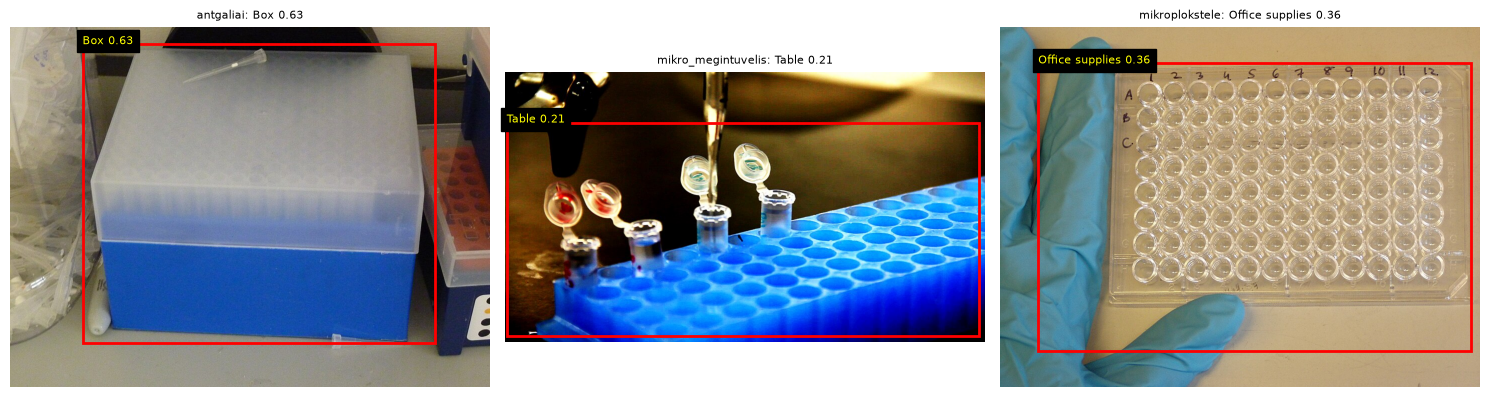

In [4]:
import tensorflow_hub as hub
from matplotlib.patches import Rectangle

detector = hub.load("https://tfhub.dev/google/openimages_v4/ssd/mobilenet_v2/1").signatures["default"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (c, img) in zip(axes, raw_images.items()):
    h, w = img.shape[:2]
    det = detector(tf.image.convert_image_dtype(img, tf.float32)[None, ...])
    boxes, scores = det["detection_boxes"].numpy(), det["detection_scores"].numpy()
    names = [n.decode() for n in det["detection_class_entities"].numpy()]
    ax.imshow(img); ax.axis("off"); shown = []
    for box, score, name in zip(boxes, scores, names):
        if score < 0.2 or len(shown) >= 5:
            continue
        y0, x0, y1, x1 = box
        ax.add_patch(Rectangle((x0 * w, y0 * h), (x1 - x0) * w, (y1 - y0) * h, fill=False, edgecolor="red", lw=2))
        ax.text(x0 * w, y0 * h, f"{name} {score:.2f}", color="yellow", fontsize=8, backgroundcolor="black")
        shown.append(f"{name} {score:.2f}")
    ax.set_title(f"{c}: {', '.join(shown) or 'nieko > 0,2'}", fontsize=8)
plt.tight_layout(); plt.show()


## 5. Semantinė segmentacija (HRNet, ADE20K)

Segmentacijos modelis kiekvienam pikseliui priskiria vieną iš ADE20K scenų klasių (siena, stalas, butelis, …). Laboratorinių reikmenų klasių ten nėra, todėl kaukė rodo plačius scenos regionus — tai **ne** prekės kontūro ar tipo nustatymas. Klasių numeriai rodomi be pavadinimų, nes čia svarbu ne konkretus vardas, o tai, kad modelis neturi mums reikalingų klasių.


antgaliai - skirtingų klasių kaukėje: 10 | išvesties forma: (384, 384, 151)


mikro_megintuvelis - skirtingų klasių kaukėje: 17 | išvesties forma: (384, 384, 151)


mikroplokstele - skirtingų klasių kaukėje: 6 | išvesties forma: (384, 384, 151)


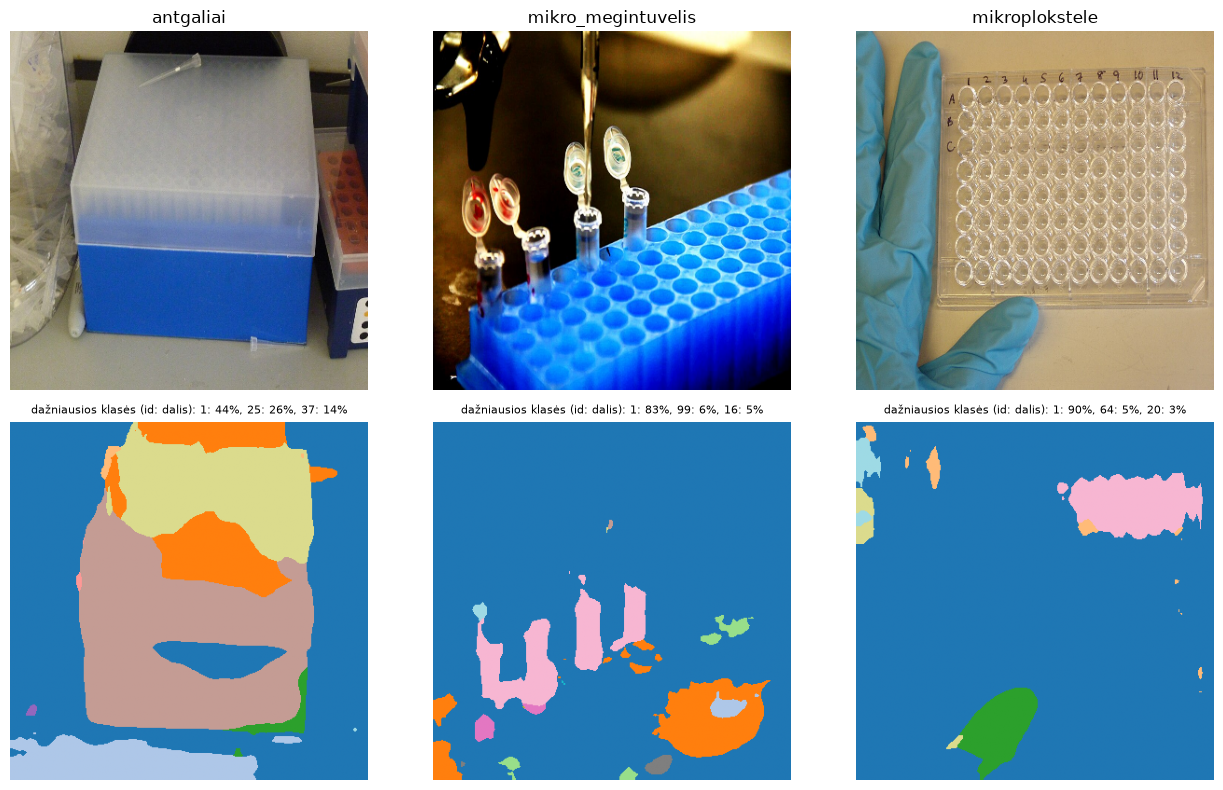

In [5]:
segmenter = hub.load("https://tfhub.dev/google/HRNet/ade20k-hrnetv2-w48/1")
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for k, (c, img) in enumerate(raw_images.items()):
    seg_in = tf.image.resize(img, (384, 384))[None, ...] / 255.0
    scores = segmenter.predict(tf.cast(seg_in, tf.float32)).numpy()[0]
    mask = scores.argmax(axis=-1)
    ids, counts = np.unique(mask, return_counts=True)
    top = sorted(zip(counts, ids), reverse=True)[:3]
    axes[0, k].imshow(tf.image.resize(img, (384, 384)).numpy().astype("uint8")); axes[0, k].set_title(c); axes[0, k].axis("off")
    axes[1, k].imshow(mask, cmap="tab20"); axes[1, k].axis("off")
    axes[1, k].set_title("dažniausios klasės (id: dalis): " + ", ".join(f"{i}: {n / mask.size:.0%}" for n, i in top), fontsize=8)
    print(c, "- skirtingų klasių kaukėje:", len(ids), "| išvesties forma:", scores.shape)
plt.tight_layout(); plt.show()


## 6. Ką bendras modelis žino ir ko nežino

- **Žino:** bendrus vaizdinius požymius (kraštus, formas, skaidrų plastiką, tinklelio raštą) ir bendras daiktų klases, kurios kartais artimos (pvz., indai, buteliai).
- **Nežino:** kliento katalogo klasių („PCR juostelė“, „96 šulinėlių plokštelė“, „filtruoti antgaliai“), tūrio (0,1 / 0,2 / 1,5 ml), sterilumo, DNazių / RNazių nebuvimo, gamintojo, SKU ar kainos. Šių savybių negalima patikimai nustatyti ir iš nuotraukos — jos yra dokumentuose ir kataloge.
- Todėl 2 dalyje bendras modelis naudojamas tik kaip **požymių ištraukiklis**, o virš jo mokoma nauja trijų mūsų klasių galvutė.
